# Figure S3c
Error of the drift prediction (dashed) and of the theorem without the exponentially small term (solid) for $\mathbb{E}[H]$ against the population size. Markers are the error computed with the exact recursion, drawn above $10^{-11}$.

In [1]:
import json

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from fixloc import style as S

d = json.load(open('data.json'))

In [2]:
CM_R = LinearSegmentedColormap.from_list('r', [S.LBLUE, S.BLUE, (0.03, 0.15, 0.35)])
RCOL = {r: CM_R(x) for r, x in zip(d['rs'], (0.2, 0.47, 0.74, 1.0))}
DASH = (0, (3, 2))

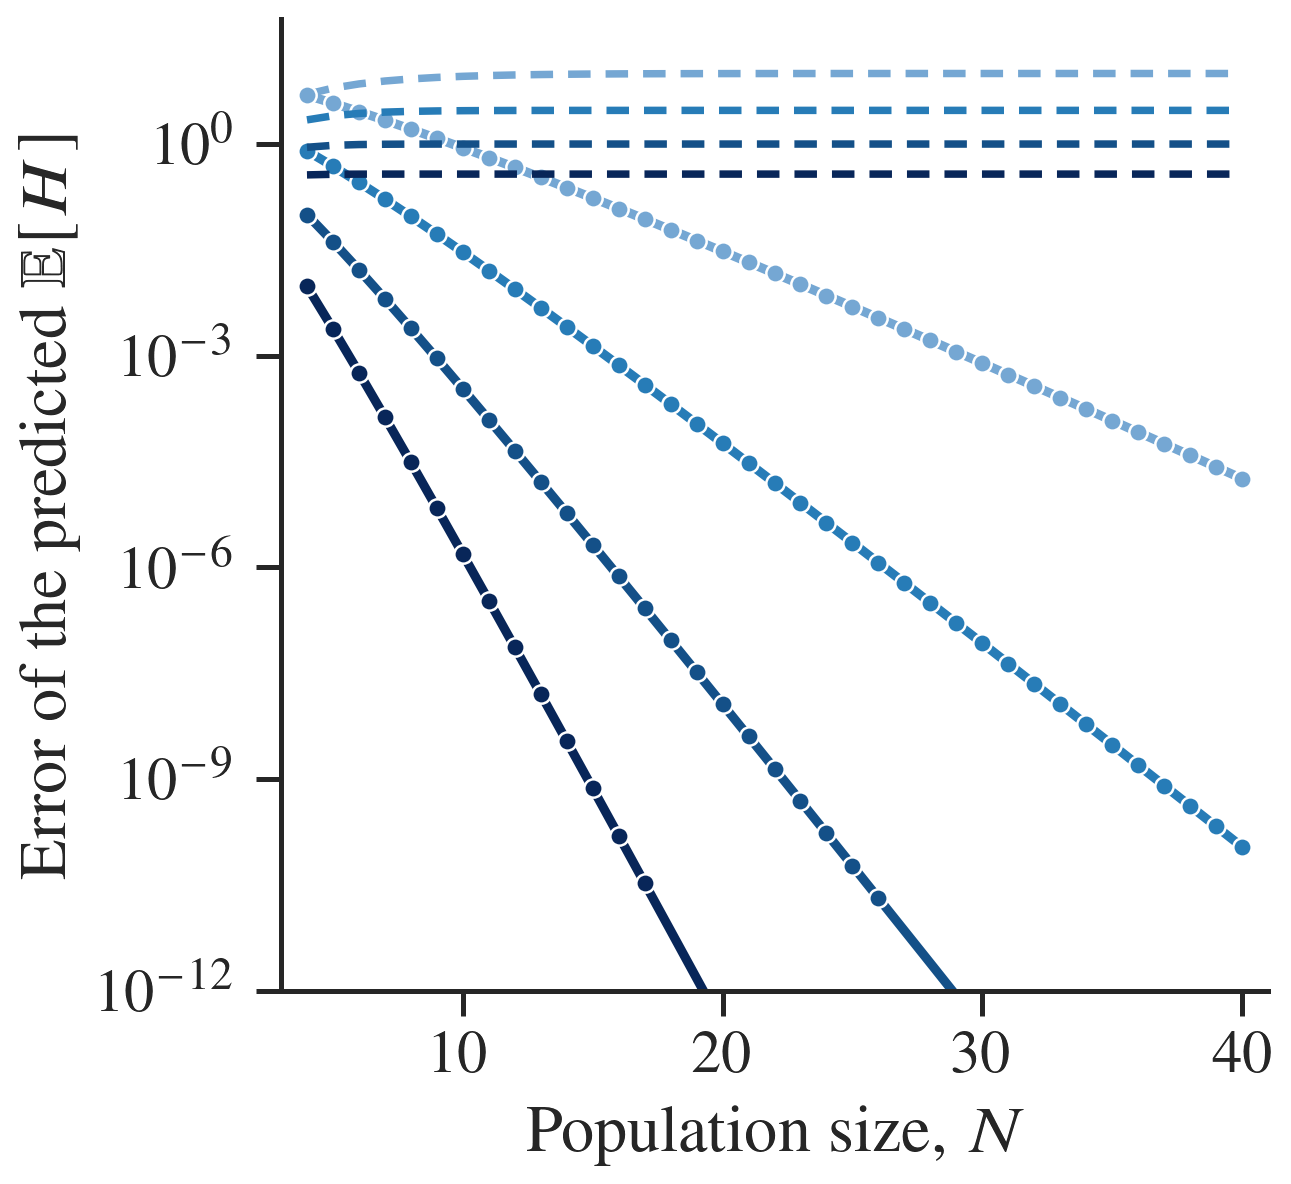

In [3]:
Nc = np.array(d['N'])
fig = plt.figure(figsize=(7.0, 5.4))
ax = fig.add_axes([0.405, 0.085, 0.235, 0.3])
for r in d['rs']:
  e = d['errors'][str(r)]
  ax.plot(Nc, e['err_drift'], color=RCOL[r], lw=0.9, ls=DASH)
  ax.plot(Nc, e['err_corrected'], color=RCOL[r], lw=1.1)
  rec = np.array(e['err_corrected_recursion'])
  keep = rec > 1e-11
  ax.plot(Nc[keep], rec[keep], ls='', marker='o', ms=2.2, mfc=RCOL[r], mec='white', mew=0.3)
ax.set_yscale('log')
ax.set_ylim(1e-12, 60)
ax.set_xlim(3, 41)
ax.set_xticks([10, 20, 30, 40])
ax.set_yticks([1e-12, 1e-9, 1e-6, 1e-3, 1])
ax.set_xlabel(r'Population size, $N$')
ax.set_ylabel(r'Error of the predicted $\mathbb{E}[H]$')
S.save_panel(fig, 'c')